# Exercício Prático I
## Aprendizado de máquina A

***Aluna: Lívia Caroline Rodrigues Pereira***

***Matrícula: 2024024003***


> O trabalho foi realizado utilizando o Drive como pasta principal, de forma que o carregamento de dados pode ser alterado para se rodar localmente (o formato estará comentado). Além disso, LLMs (Gemini 3.1 Pro) foram utilizadas para auxiliar na geração, organização e entendimento dos códigos. A parte de esquemas e explicação estão no pdf desse exercício.




In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


Mounted at /content/drive


In [2]:
# Definir o caminho dos dados no Google Drive (ajuste se estiver dentro de outra pasta no seu Drive)
data_dir = '/content/drive/MyDrive/database/2026.2/am/ep1/dados_tp1'

In [3]:
# Carregar arquivos
# Se local. precisaria redefinir data_dir

df1 = pd.read_csv(os.path.join(data_dir, 'secao1.csv'))
df2 = pd.read_csv(os.path.join(data_dir, 'secao2.csv'))
df3 = pd.read_csv(os.path.join(data_dir, 'secao3.csv'))

## TAREFA 1: OLS 1D

Implementação do método de Mínimos Quadrados Ordinários (OLS) em 1D pela solução fechada, derivada diretamente das equações normais. A partir dessa implementação, avaliação utilizando métricas clássicas como o Erro Quadrático Médio (MSE), o Erro Absoluto Médio (MAE) e o coeficiente de determinação R2, além de visualizações gráficas dos resultados.

a) Construção de X e  β

In [4]:
x = df1['x'].values
y = df1['y'].values.reshape(-1, 1)

n = len(x)
# Construção da matriz de projeto X com intercepto (coluna de 1s)
X = np.c_[np.ones(n), x]

In [5]:
# (X^T * X)⁻¹(X^T)*y
beta_ols = np.linalg.inv(X.T @ X) @ X.T @ y

b) Previsão e Resíduos

In [6]:
y_pred = X @ beta_ols
residuos = y - y_pred

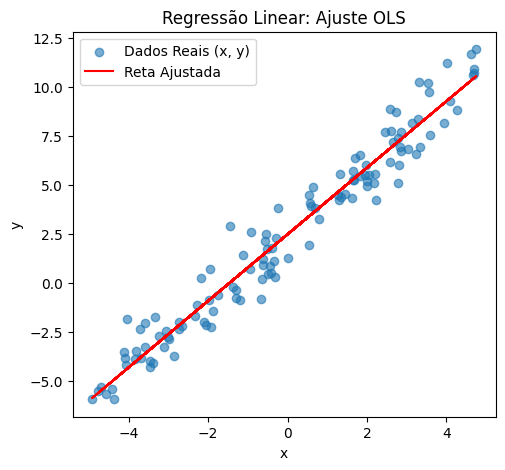

In [7]:
# Gráfico de Dispersão e Reta Ajustada
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(x, y, label='Dados Reais (x, y)', alpha=0.6)
plt.plot(x, y_pred, color='red', label='Reta Ajustada')
plt.title('Regressão Linear: Ajuste OLS')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()

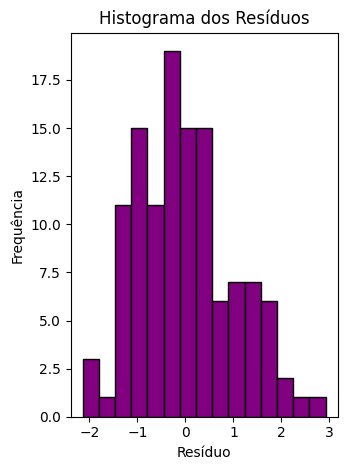

In [8]:
# Histograma dos Resíduos
plt.subplot(1, 2, 2)
plt.hist(residuos, bins=15, color='purple', edgecolor='black')
plt.title('Histograma dos Resíduos')
plt.xlabel('Resíduo')
plt.ylabel('Frequência')
plt.tight_layout()
plt.show()

c) Métricas

In [9]:
MSE = np.mean(residuos**2)
MAE = np.mean(np.abs(residuos))
SST = np.sum((y - np.mean(y))**2)
SSR = np.sum(residuos**2)
R2 = 1 - (SSR / SST)

tabela_metricas = pd.DataFrame({
    'Métrica': ['MSE', 'MAE', 'R²'],
    'Valor': [MSE, MAE, R2]
})

# Arredondamento para 4 casas decimais
tabela_metricas['Valor'] = tabela_metricas['Valor'].round(4)
tabela_metricas

,Métrica,Valor
0,MSE,1.0155
1,MAE,0.8025
2,R²,0.9548


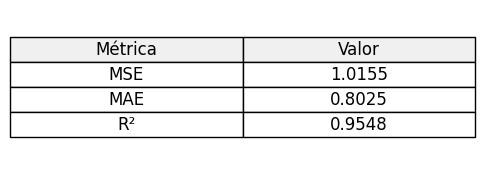

In [23]:
# Como imagem
fig, ax = plt.subplots(figsize=(5, 2))

# Escondemos os eixos do gráfico, já que queremos apenas desenhar a tabela
ax.axis('tight')
ax.axis('off')

# 3. Desenhando a tabela na figura
tabela_img = ax.table(
    cellText=tabela_metricas.values,
    colLabels=tabela_metricas.columns,
    cellLoc='center',
    loc='center',
    colColours=['#f0f0f0'] * len(tabela_metricas.columns) # Adiciona um fundo cinza claro no cabeçalho
)

# 4. Ajustes estéticos (tamanho da fonte e espaçamento das células)
tabela_img.auto_set_font_size(False)
tabela_img.set_fontsize(12)
tabela_img.scale(1.2, 1.5) # (escala_largura, escala_altura)

Letras d) e e) enviadas no pdf junto a esse código no arquivo compactado

## TAREFA 2: Ridge Regression

Implementação do método de Ridge Regression e comparar com OLS, entendendo onde ele (OLS) falha/não funciona.

In [13]:
def ridge_regression(X, y, lambda_val):
    # Dimensão de p (número de colunas de X)
    p = X.shape[1]

    # Matriz Identidade
    I = np.eye(p)
    # Zera o primeiro elemento para NÃO regularizar o intercepto
    I[0, 0] = 0

    # Cálculo: beta_ridge = (X^T * X + lambda * I)^-1 * X^T * y
    beta_ridge = np.linalg.inv(X.T @ X + lambda_val * I) @ X.T @ y
    return beta_ridge

a) Treino e Teste

In [14]:
n_samples = len(df2)
train_size = int(0.70 * n_samples)

In [15]:
np.random.seed(64)

indices = np.random.permutation(n_samples)
train_idx, test_idx = indices[:train_size], indices[train_size:]

train_data, test_data = df2.iloc[train_idx], df2.iloc[test_idx]

In [16]:
# Definição de X e y (Assumindo que há colunas x1, x2, y)
X_train2 = np.c_[np.ones(len(train_data)), train_data[['x1', 'x2']].values]
y_train2 = train_data['y'].values.reshape(-1, 1)

X_test2 = np.c_[np.ones(len(test_data)), test_data[['x1', 'x2']].values]
y_test2 = test_data['y'].values.reshape(-1, 1)

# OLS puro (lambda = 0)
beta_ols2 = ridge_regression(X_train2, y_train2, 0)

b) Caminho dos coeficientes

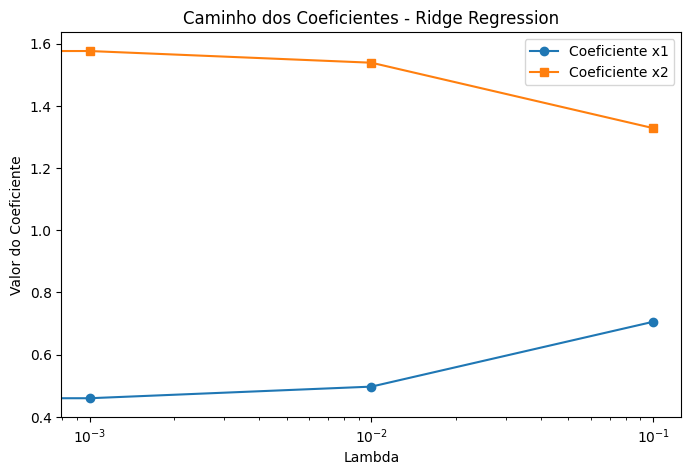

In [17]:
lambdas = [0, 10**-3, 10**-2, 10**-1]
coefs_path = []

for l in lambdas:
    beta_r = ridge_regression(X_train2, y_train2, l)
    coefs_path.append(beta_r.flatten()) # flatten para facilitar o log

coefs_path = np.array(coefs_path)

plt.figure(figsize=(8, 5))
plt.plot(lambdas, coefs_path[:, 1], marker='o', label='Coeficiente x1')
plt.plot(lambdas, coefs_path[:, 2], marker='s', label='Coeficiente x2')
plt.xscale('log') # Escala logarítmica para ver melhor a contração
plt.xlabel('Lambda')
plt.ylabel('Valor do Coeficiente')
plt.title('Caminho dos Coeficientes - Ridge Regression')
plt.legend()
plt.show()

c) Falha da OLS e Validação Cruzada

In [18]:
y3 = df3['y'].values.reshape(-1, 1)

# As colunas preditoras são todas exceto 'y'
X3_raw = df3.drop(columns=['y']).values
n3 = len(X3_raw)

# Adicionando o intercepto
X3 = np.c_[np.ones(n3), X3_raw]
p3 = X3.shape[1]

print(f"Dimensões: n = {n3} observações, p = {p3} parâmetros (incluindo intercepto).")


Dimensões: n = 12 observações, p = 21 parâmetros (incluindo intercepto).


In [19]:

# 1. Demonstração de falha do OLS
cond_number = np.linalg.cond(X3.T @ X3)
print(f"Número de condicionamento de (X^T * X): {cond_number:.2e}")
if cond_number > 1e15:
    print("A matriz (X^T * X) é computacionalmente singular. O OLS puro falhará e apresentará instabilidade numérica severa.\n")


Número de condicionamento de (X^T * X): 3.12e+17
A matriz (X^T * X) é computacionalmente singular. O OLS puro falhará e apresentará instabilidade numérica severa.



In [20]:
# 2. Validação Cruzada K-Fold
K = 4
lambdas_cv = [10**-4, 10**-3, 10**-2, 10**-1, 1, 10, 100]

# Criação manual dos folds
indices = np.random.permutation(n3)
fold_sizes = np.full(K, n3 // K)
fold_sizes[:n3 % K] += 1 # Distribui o resto para que a divisão fique equilibrada

current = 0
folds = []
for fold_size in fold_sizes:
    start, stop = current, current + fold_size
    folds.append(indices[start:stop])
    current = stop

mse_medios = []

# Loop pela malha de lambdas
for l in lambdas_cv:
    mse_folds = []

    # Loop pelos K folds
    for i in range(K):
        # Seleciona o fold de validação
        idx_test = folds[i]
        # Agrupa os restantes para treino
        idx_train = np.hstack([folds[j] for j in range(K) if j != i])

        X_train_cv, y_train_cv = X3[idx_train], y3[idx_train]
        X_test_cv, y_test_cv = X3[idx_test], y3[idx_test]

        # Ajusta o modelo nos dados de treino usando a função ridge_regression feita anteriormente
        beta_cv = ridge_regression(X_train_cv, y_train_cv, l)

        # Avalia no fold de validação
        y_pred_cv = X_test_cv @ beta_cv
        mse_val = np.mean((y_test_cv - y_pred_cv)**2)
        mse_folds.append(mse_val)

    mse_medios.append(np.mean(mse_folds))

# Identificação do lambda ótimo (lambda*)
best_idx = np.argmin(mse_medios)
lambda_star = lambdas_cv[best_idx]
print(f"-> Melhor lambda (λ*): {lambda_star} | MSE médio de validação: {mse_medios[best_idx]:.4f}")

-> Melhor lambda (λ*): 0.01 | MSE médio de validação: 7.1500


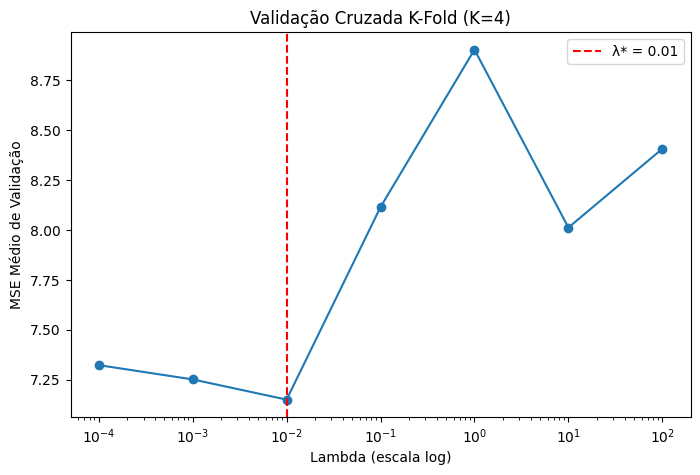

In [21]:
# Gráfico MSE médio vs Lambda
plt.figure(figsize=(8, 5))
plt.plot(lambdas_cv, mse_medios, marker='o', linestyle='-')
plt.axvline(x=lambda_star, color='red', linestyle='--', label=f'λ* = {lambda_star}')
plt.xscale('log')
plt.xlabel('Lambda (escala log)')
plt.ylabel('MSE Médio de Validação')
plt.title('Validação Cruzada K-Fold (K=4)')
plt.legend()
plt.show()

d) Reajustando com λ*

In [22]:
beta_star = ridge_regression(X3, y3, lambda_star)

# Previsões finais e resíduos
y_pred_final = X3 @ beta_star
residuos_final = y3 - y_pred_final

# Cálculo das Métricas
MSE_final = np.mean(residuos_final**2)
MAE_final = np.mean(np.abs(residuos_final))
SST_final = np.sum((y3 - np.mean(y3))**2)
SSR_final = np.sum(residuos_final**2)
R2_final = 1 - (SSR_final / SST_final)

# Tabela organizada com pandas
tabela_final = pd.DataFrame({
    'Métrica': ['MSE', 'MAE', 'R²'],
    'Valor Final (Ridge com λ*)': [MSE_final, MAE_final, R2_final]
})

tabela_final['Valor Final (Ridge com λ*)'] = tabela_final['Valor Final (Ridge com λ*)'].round(4)

# Renderiza a tabela no Jupyter
tabela_final

,Métrica,Valor Final (Ridge com λ*)
0,MSE,0.1766
1,MAE,0.3580
2,R²,0.9735


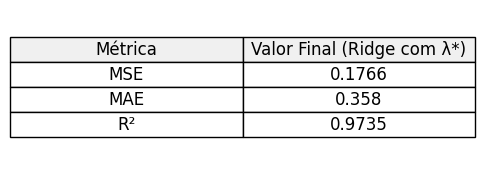

In [24]:
# Como imagem
fig, ax = plt.subplots(figsize=(5, 2))

# Escondemos os eixos do gráfico, já que queremos apenas desenhar a tabela
ax.axis('tight')
ax.axis('off')

# 3. Desenhando a tabela na figura
tabela_img = ax.table(
    cellText=tabela_final.values,
    colLabels=tabela_final.columns,
    cellLoc='center',
    loc='center',
    colColours=['#f0f0f0'] * len(tabela_final.columns) # Adiciona um fundo cinza claro no cabeçalho
)

# 4. Ajustes estéticos (tamanho da fonte e espaçamento das células)
tabela_img.auto_set_font_size(False)
tabela_img.set_fontsize(12)
tabela_img.scale(1.2, 1.5) # (escala_largura, escala_altura)

Letras e) e f) enviadas no pdf junto a esse código no arquivo compactado

## Finalizando

In [ ]:
print("That's all folks!")

That's all folks!
